In [1]:
from prophet import Prophet
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Reload data
df = pd.read_csv('/workspaces/Major_project/data/processed/district_level_data.csv')

# Aggregate yearly
yearly_trend = df.groupby('year').agg({'severity_score': 'sum'}).reset_index()

# Use mid-year dates (June 30th) for BOTH training and forecasting
prophet_df = pd.DataFrame({
    'ds': pd.to_datetime(yearly_trend['year'].astype(str) + '-06-30'),
    'y': yearly_trend['severity_score']
})

print(prophet_df)

          ds          y
0 2017-06-30  2219987.0
1 2018-06-30  2382332.0
2 2019-06-30  2559149.0
3 2020-06-30  2345987.0
4 2021-06-30  2692687.0
5 2022-06-30  2815576.0
6 2023-06-30  2787535.0


In [2]:
id_cols = ['id', 'year', 'state_name', 'state_code',
           'district_name', 'district_code', 'registration_circles',
           'total_crimes', 'severity_score', 'risk_level', 'target', 'next_year_severity']

crime_cols = [c for c in df.columns
              if c not in id_cols
              and not c.endswith('.1')]  # exclude duplicates

print(f"Clean feature count: {len(crime_cols)}")
print(crime_cols[:5])
print(crime_cols[-5:])

Clean feature count: 44
['murder_with_rape_gang_rape', 'dowry_deaths', 'abetment_to_suicide_of_women', 'miscarriage', 'acid_attack']
['offences_of_pocso_act', 'pocso_act_unnatural_offences', 'indecent_representation_of_women', 'latitude', 'longitude']


In [3]:
prophet_model = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95
)
prophet_model.fit(prophet_df)
print("✅ Prophet retrained.")

16:16:08 - cmdstanpy - INFO - Chain [1] start processing
16:16:08 - cmdstanpy - INFO - Chain [1] done processing


✅ Prophet retrained.


In [4]:
# Forecast — use SAME mid-year convention
future_dates = pd.DataFrame({
    'ds': pd.to_datetime(['2024-06-30', '2025-06-30'])
})
forecast = prophet_model.predict(future_dates)

print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']])

          ds          yhat    yhat_lower    yhat_upper
0 2024-06-30  2.931047e+06  2.753144e+06  3.126775e+06
1 2025-06-30  3.027719e+06  2.837936e+06  3.217587e+06


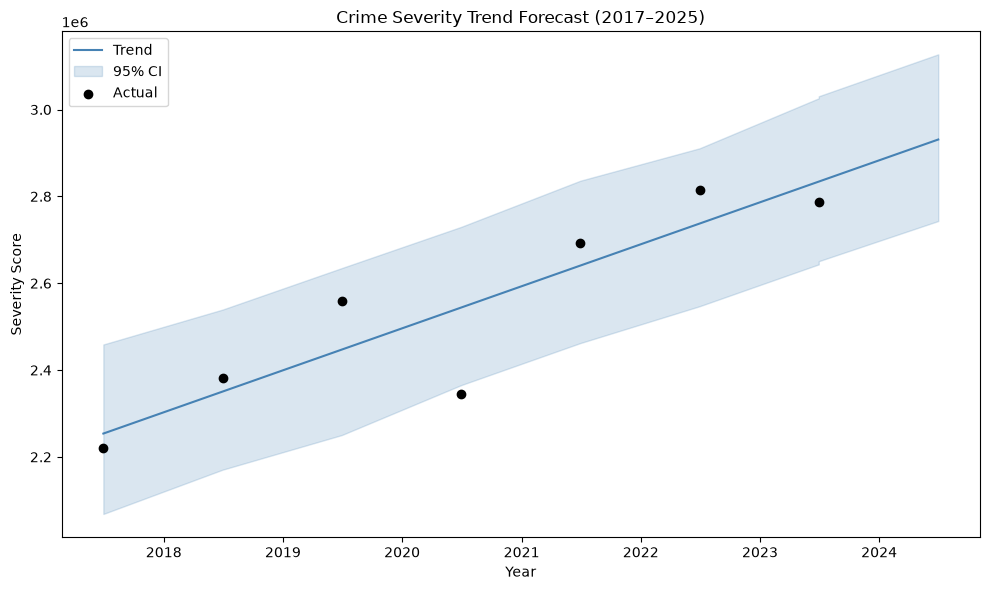

In [5]:
# Forecast including history
future = prophet_model.make_future_dataframe(periods=2, freq='YE', include_history=True)
# Force mid-year convention
future['ds'] = pd.to_datetime(future['ds'].dt.year.astype(str) + '-06-30')

forecast = prophet_model.predict(future)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(forecast['ds'], forecast['yhat'], label='Trend', color='steelblue')
ax.fill_between(forecast['ds'], forecast['yhat_lower'], forecast['yhat_upper'],
                alpha=0.2, color='steelblue', label='95% CI')
ax.scatter(prophet_df['ds'], prophet_df['y'], color='black', label='Actual', zorder=5)
ax.set_title("Crime Severity Trend Forecast (2017–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Severity Score")
ax.legend()
plt.tight_layout()
plt.savefig('/workspaces/Major_project/reports/prophet_forecast.png', dpi=150)
plt.show()

In [6]:
joblib.dump(prophet_model, '../models/prophet_model.pkl')
print("✅ Prophet model re-saved.")

✅ Prophet model re-saved.


In [7]:
loaded = joblib.load('../models/prophet_model.pkl')
print("✅ Model reloaded successfully.")

✅ Model reloaded successfully.


In [8]:
import joblib
import pandas as pd

# Reload data
df = pd.read_csv('/workspaces/Major_project/data/processed/district_level_data.csv')

# Identify non-feature columns
id_cols = ['id', 'year', 'state_name', 'state_code',
           'district_name', 'district_code', 'registration_circles',
           'total_crimes', 'severity_score', 'risk_level', 'target', 'next_year_severity']

# Crime columns = everything else, and NOT duplicates (no .1 suffix)
crime_cols = [c for c in df.columns
              if c not in id_cols
              and not c.endswith('.1')]

print(f"Total columns in dataset: {len(df.columns)}")
print(f"Clean feature count: {len(crime_cols)}")
print(f"\nFirst 5: {crime_cols[:5]}")
print(f"Last 5: {crime_cols[-5:]}")

# Overwrite the saved file
joblib.dump(crime_cols, '/workspaces/Major_project/models/feature_cols.pkl')
print("\n✅ feature_cols.pkl updated (no duplicates)")

Total columns in dataset: 53
Clean feature count: 44

First 5: ['murder_with_rape_gang_rape', 'dowry_deaths', 'abetment_to_suicide_of_women', 'miscarriage', 'acid_attack']
Last 5: ['offences_of_pocso_act', 'pocso_act_unnatural_offences', 'indecent_representation_of_women', 'latitude', 'longitude']

✅ feature_cols.pkl updated (no duplicates)
